In [6]:
'''
Useful Firedrake functions and methods for this notebook:

IntervalMesh(n, 1.0) - Divides the radial interval into n finite elements.
FunctionSpace(mesh, "CG", 1) - Defines the allowed shape of q: continuous straight-line pieces between mesh nodes. V is this space.
SpatialCoordinate(mesh)[0] - Creates the symbolic radial coordinate rho, for use in formulas. It is not an array of node positions.
Function(V) - Creates an object that can store numerical values at the mesh nodes. q_old stores the previous solution; q receives the new solution.
TrialFunction(V) - A symbolic placeholder for the unknown (q^{n+1}) when writing the left side of the linear problem. It does not itself store the answer.
TestFunction(V) - A symbolic weighting function (v). Firedrake uses it to turn the weak form into one equation per degree of freedom.
grad(...) - Takes a spatial gradient. On this 1D mesh, grad(q) represents the radial derivative (dq/drho).
dot(a, b) - Takes the dot product of two gradients. Here it represents (q_rho v_rho).
dx	Means “integrate over the mesh.” It is an integration measure, not a Python function: rho*q*dx represents (int_0^1 rho q,drho).
DirichletBC(V, 1.0, 2)	Sets (q=1) at boundary marker 2, the right end (rho=1).
LinearVariationalProblem(lhs, rhs, q, bcs=[bc])	Packages the equation lhs = rhs, the place to put its answer (q), and the boundary condition.
LinearVariationalSolver(problem)	Prepares a solver for that problem. Keeping this object lets you reuse it at every time step.
assemble(2*rho*q*dx)	Evaluates the integral and returns a number: the area-weighted mean concentration.


q_old.assign(0.0)	Fills q_old with the initial value zero.
solver.solve()	Actually solves one time step and puts the result in q.
q_old.assign(q)	Copies the new solution into q_old, ready for the next step.
Function(V).interpolate(rho)	Evaluates the coordinate expression at the function-space nodes, giving a function containing their radial positions. Interpolation guide
q.dat.data_ro	Reads the stored nodal values of q as an array. ro means read-only. In the notebook, .copy() preserves those values before the next solve.
.dat — access the storage for that Functions degrees of freedom.
.data_ro — read those values as a read-only NumPy array (ro = read-only).

Side: E is not included, but it is included in the equations for completeness. 
The diffusion equation is not stress assisted, so E has no effect on the solution.
'''
from firedrake import *
import numpy as np
import matplotlib.pyplot as plt

R = 100e-9    
D = 2.06e-18     
c0 = 1.0         
cmax = 88.67  
dt = 0.5         

mesh = IntervalMesh(160, 1.0)
V = FunctionSpace(mesh, "CG", 1)
x = SpatialCoordinate(mesh)[0]

q_old = Function(V)
q = Function(V)
q_old.assign(0.0)

bc = DirichletBC(V, 1.0, 2)  # q = 1 at the surface
bc.apply(q_old)


In [ ]:

trial = TrialFunction(V)
test = TestFunction(V)

lhs = (
    x * trial * test / dt
    + (D / R**2) * x * dot(grad(trial), grad(test))
) * dx
rhs = x * q_old * test / dt * dx

problem = LinearVariationalProblem(lhs, rhs, q, bcs=[bc])
solver = LinearVariationalSolver(problem)

# 161 equally spaced nodes, already confirmed to match Firedrake's order.
node_x = np.linspace(0, 1, 161)

snapshot_steps = [5, 15, 20, 25]
rates = {}

# solve every 0.5 s; save only the requested steps.
for step in range(1, 26):
    solver.solve()
    #solved by backward Euler, so the rate is the change in concentration over the time step.
    if step in snapshot_steps:
        dc_dt = (cmax - c0) * (
            q.dat.data_ro - q_old.dat.data_ro
        ) / dt
        rates[step * dt] = dc_dt

    q_old.assign(q)



2.5 s: maximum rate = 9.905 kmol/m³/s at r/R = 0.975
7.5 s: maximum rate = 3.038 kmol/m³/s at r/R = 0.950
10 s: maximum rate = 2.270 kmol/m³/s at r/R = 0.938
12.5 s: maximum rate = 1.810 kmol/m³/s at r/R = 0.931


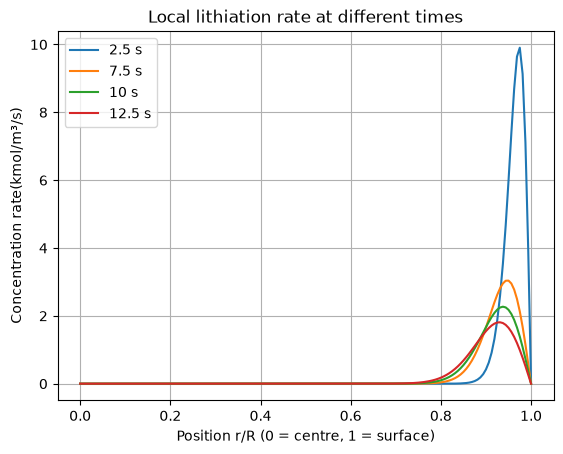

In [ ]:

for time, rate in rates.items():
    label = f"{time:g} s"
    plt.plot(node_x, rate, label=label)

    fastest = np.argmax(rate)
    print(
        f"{label}: maximum rate = {rate[fastest]:.3f} "
        f"kmol/m³/s at r/R = {node_x[fastest]:.3f}"
    )

plt.xlabel("Position r/R (0 = centre, 1 = surface)")
plt.ylabel("Concentration rate(kmol/m³/s)")
plt.title("Local lithiation rate at different times")
plt.legend()
plt.grid(True)
plt.show()